# E82: Where does teacher training sit on the masked reading of Qwen's first update?

*2026-11-04. A thin explanation of `reports/analyses/2026-11-04_analysis_e82-teacher-on-e68.md`, which holds the record. No independent check.*

*For D1, a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement.*

**The answer.** Teacher training closes about a twelfth of the KL gap under the original model's masks, the same order as adding the whole update directly. An earlier figure of about a sixth came from other rows and stochastic masks. So this reading cannot tell a good placement from the update itself, and that map still has no method shown good.

## What we were trying to test

An earlier plot compared do-nothing, least squares and the adjoint split on one reading, with a teacher-training point borrowed from another. That point sat above the whole-update line, which invited a comparison the readings could not support. So we read one saved teacher-training state on the same rows and masks as the others, and nothing was trained.

The state is teacher training towards the first update, with about 200 often-on columns per matrix moved, Γ and Δ frozen, and no masks in the loss. It is scored on 128 maths rows of 256 tokens, with masks from Γ on the original model's forward and Δ off.

**The share closed.** $K$ is the forward KL from the fine-tuned model with no masks to the masked forward, per position. $K_D$ is that for do-nothing, and $K_0$ is the KL from the original model to its own masked forward. The share closed is $(K_D - K) / (K_D - K_0)$, so 0 is do-nothing and 1 is as close as the original decomposition is to the original model. The faithful line is $K \le 1.5 K_0$.

**Gain kept.** The drop in next-token loss under the masks, as a share of the drop the fine-tune achieves with no masks. Do-nothing reads 0.

## What we expected, and why

A weak lean that the share would land between 0.05 and 0.30, since the earlier reading gave 0.16. A firm lean that it would stay under the faithful line. No lean on gain kept.

## What we observed

### Does teacher training close more of the gap than the whole update?


share closed 0.083, faithful line 0.973, gain kept 0.247


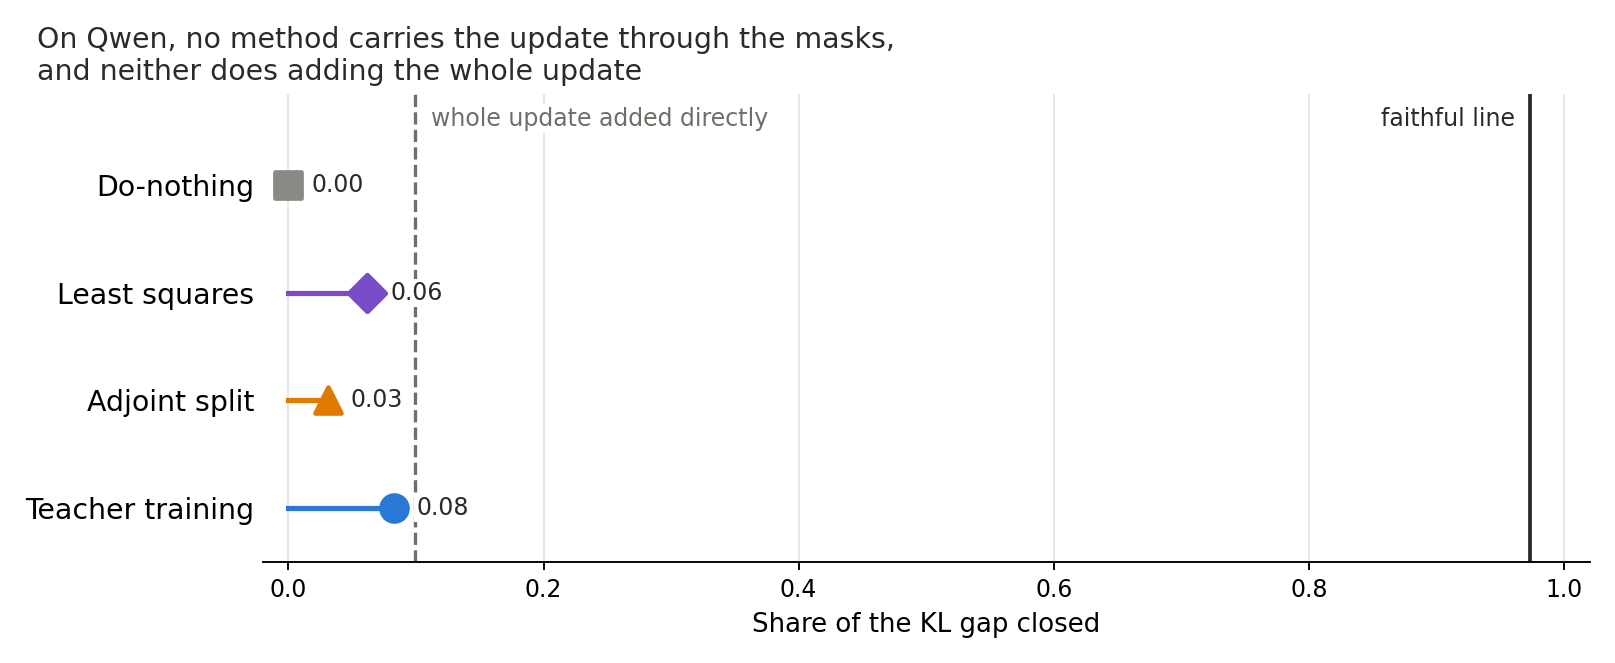

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display

ROOT = Path("../experiments/qwen_pass_test")
R = json.loads((ROOT / "results" / "teacher_clean.json").read_text())

def show(name):
    display(Image(filename=str(ROOT / "figures" / name), width=760))

print(f"share closed {R['share_closed']:.3f}, faithful line {R['faithful_line']:.3f}, gain kept {R['gain_kept']:.3f}")
show("gap_closed_clean.png")


**Reading it.** No. It closes 0.083 against 0.099 for the whole update. Least squares closes 0.062 and the adjoint split 0.031, with the faithful line at 0.97. This is one state on one update with no noise floor, so "below" is not a ranking.

### How much of the fine-tune's gain survives?


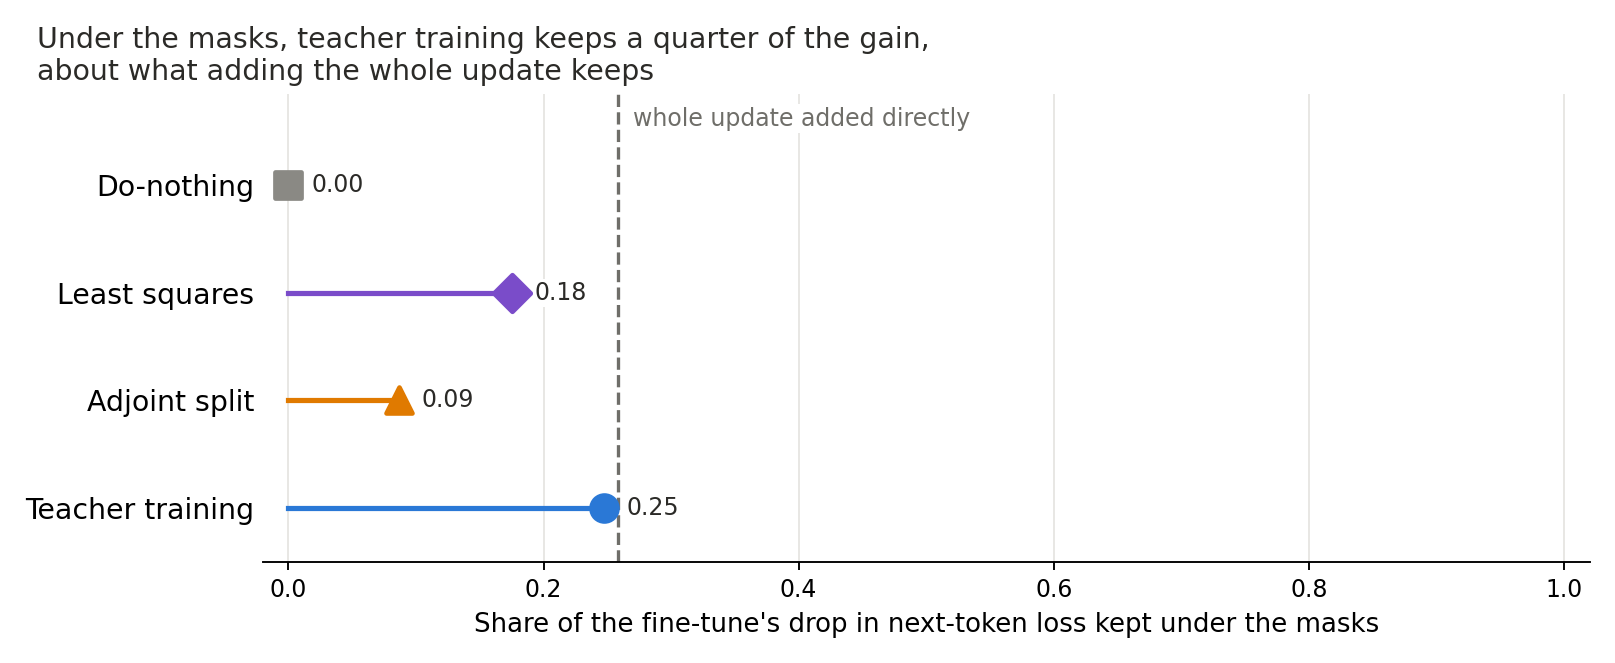

In [2]:
show("gain_kept_clean.png")


**Reading it.** A quarter. Teacher training keeps 0.247 against 0.258 for the whole update. Least squares keeps 0.175 and the adjoint split 0.087, the same order as the share closed.

## What we learned

The move from about a sixth to about a twelfth removes the appearance that teacher training gets past the masks. Without masks this state copies the fine-tuned model almost exactly, so the loss here arises under the masks and not in the training. For `GOALS.md`, this reading does not show the state faithful.

## How compelling is the evidence

One seed, one update, one state, frozen masks. A low reading may be the masks losing any change this size, and not the map. Unchanged components reproduce the earlier do-nothing per row to about 1e-6 on the first 8 rows. A quarter of the rows were in the state's training pool, and they read the same as the rest.

## Surprises

None against the filed leans. The result landing below the whole-update line is the thing that changed.

## What next

Nothing runs from this. Whether teacher training is the map rests on other reads, the clean table and the adversary.

## Scorecard

| Filed | Rule | Read | Verdict |
|---|---|---|---|
| Control | do-nothing K and nll per row on 8 rows within 1e-3 relative | K 9.7e-7, nll 0 | held |
| Share closed, weak lean | 0.05 to 0.30 | 0.083 | held |
| Faithful, firm lean | below the line, 0.97 | 0.083 | held |
| Gain kept | no lean, reported | 0.247 | reported |

## Departures from the literature

VPD scores a decomposition on the model it was fitted to, under its own masks. Here the masks come from Γ on the original model while the state's weights differ, with Δ off, which is this project's reading. Teacher training has no published source.

## Not run

A second seed or state. The other three updates. The earlier rows or stochastic masks on these states, which would separate the causes of the drop. A noise floor between states. Masks recomputed on the state's own forward. What Γ reading V rounded to bf16 does to the masks.

## Provenance

Cluster job 51327, L40, `debug` QoS, about 3 minutes, $0. Code `experiments/qwen_pass_test/teacher_read.py`, results `experiments/qwen_pass_test/results/teacher_clean.json`, figures in `experiments/qwen_pass_test/figures/`.
